# 04: TruLens RAG Triad Evaluation

**Document:** JPMorgan Chase & Co. 2025 Annual Report
**Scope:** 20 Easy Benchmark Questions
**Framework:** TruLens 2.x — Real `LLMProvider` API
**Feedback Provider:** Groq `llama-3.3-70b-versatile`

### The TruLens RAG Triad

| Dimension | Question answered | Guards against |
|---|---|---|
| **Context Relevance** | Is the retrieved context relevant to the query? | Noisy / off-topic retrieval |
| **Groundedness** | Is the answer grounded in the context? | Hallucination |
| **Answer Relevance** | Does the answer address the question? | Verbose but non-responsive answers |

> TruLens's `LLMProvider` base class ships its own standardized prompts for each
> metric (sourced from the TruLens paper). We only supply the LLM backend (Groq).
> This is different from notebook 02 where we wrote our own judge prompts.


In [1]:
import sys, os, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from dotenv import load_dotenv

load_dotenv()

BASE_DIR = Path.cwd()
if BASE_DIR.name == "evaluation":
    BASE_DIR = BASE_DIR.parent
sys.path.insert(0, str(BASE_DIR))

from agent.tools import retrieve_chunks, generate_grounded_answer, OLLAMA_URL

GROQ_API_KEY = os.getenv("GROQ_API_KEY")
if not GROQ_API_KEY:
    raise EnvironmentError("GROQ_API_KEY not set in .env")

print(f"Retrieval             : Ollama @ {OLLAMA_URL}")
print(f"Synthesis & TruLens   : Groq llama-3.3-70b-versatile")

[*] Agent Orchestrator  : Ollama 'qwen3.5:9b' @ http://localhost:11434
Retrieval             : Ollama @ http://localhost:11434
Synthesis & TruLens   : Groq llama-3.3-70b-versatile


## 1. Wire Groq into TruLens `LLMProvider`

In [2]:
from trulens.feedback import LLMProvider
from groq import Groq

class GroqProvider(LLMProvider):
    """
    Connects TruLens's built-in metric methods to Groq's llama-3.3-70b-versatile.

    TruLens's LLMProvider base class owns the metric *prompts* (context_relevance,
    groundedness_measure_with_cot_reasons, relevance, etc.). We only implement
    `generate_score` and `generate_score_and_reasons` so TruLens can call Groq
    to actually run those prompts.
    """
    model_engine: str = "llama-3.3-70b-versatile"

    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        object.__setattr__(self, "_groq", Groq(api_key=GROQ_API_KEY))

    def generate_score(self, system_prompt: str, user_prompt: str,
                       min_score_val: int = 0, max_score_val: int = 10,
                       temperature: float = 0.0) -> float:
        """Called by every TruLens metric method to get a numeric score."""
        resp = self._groq.chat.completions.create(
            model=self.model_engine,
            messages=[
                {"role": "system", "content": system_prompt},
                {"role": "user",   "content": user_prompt},
            ],
            temperature=temperature,
            max_tokens=16,
        )
        raw = resp.choices[0].message.content.strip()
        # TruLens expects a float in [0, 1] — parse from response
        import re
        nums = re.findall(r"[0-9]+\.?[0-9]*", raw)
        if nums:
            val = float(nums[0])
            # Normalize if model returned a 0-10 scale
            if val > 1.0:
                val = val / max_score_val
            return min(max(val, 0.0), 1.0)
        return 0.0

    def generate_score_and_reasons(self, system_prompt: str, user_prompt: str,
                                   min_score_val: int = 0, max_score_val: int = 10,
                                   temperature: float = 0.0):
        """Called by *_with_cot_reasons variants — returns (score, reasons dict)."""
        resp = self._groq.chat.completions.create(
            model=self.model_engine,
            messages=[
                {"role": "system", "content": system_prompt},
                {"role": "user",   "content": user_prompt},
            ],
            temperature=temperature,
            max_tokens=512,
        )
        raw = resp.choices[0].message.content.strip()
        import re
        nums = re.findall(r"[0-9]+\.?[0-9]*", raw)
        score = 0.0
        if nums:
            val = float(nums[0])
            score = min(max(val / max_score_val if val > 1.0 else val, 0.0), 1.0)
        return score, {"reason": raw}


provider = GroqProvider()
print("GroqProvider initialized — TruLens metric methods now backed by Groq.")
print(f"Available metrics (sample): context_relevance, groundedness_measure_with_cot_reasons, relevance")


Package jsonschema not present in requirements.


GroqProvider initialized — TruLens metric methods now backed by Groq.
Available metrics (sample): context_relevance, groundedness_measure_with_cot_reasons, relevance


## 2. Load Ground Truth (20 Easy Questions)

In [3]:
gt_path = BASE_DIR / "evaluation" / "ground_truth_dataset.json"
with open(gt_path, "r", encoding="utf-8") as f:
    gt_data = json.load(f)

easy_questions = [q for q in gt_data["questions"] if q.get("difficulty") == "easy"]
print(f"Loaded {len(easy_questions)} easy questions.")


Loaded 20 easy questions.


## 3. Run RAG Pipeline & Score the RAG Triad

In [4]:
triad_records = []

for idx, q in enumerate(easy_questions, 1):
    qid   = q["id"]
    query = q["question"]

    # Stage 1: Hybrid retrieval (Ollama dense + BM25 + BGE rerank)
    context = retrieve_chunks.invoke({"query": query, "limit": 5})

    # Stage 2: Grounded answer synthesis (Groq Llama 3.3 70B)
    response = generate_grounded_answer.invoke({
        "question":           query,
        "retrieved_evidence": context,
        "provider":           "groq",
    })

    # Stage 3: TruLens RAG Triad via Groq
    # These methods use TruLens's own standardized prompt templates internally
    try:
        ctx_rel, ctx_reasons = provider.context_relevance_with_cot_reasons(
            question=query, context=context
        )
    except Exception as e:
        ctx_rel, ctx_reasons = 0.0, {"reason": str(e)}
        print(f"  [!] context_relevance error: {e}")

    try:
        grounded, gr_reasons = provider.groundedness_measure_with_cot_reasons(
            source=context, statement=response
        )
    except Exception as e:
        grounded, gr_reasons = 0.0, {"reason": str(e)}
        print(f"  [!] groundedness error: {e}")

    try:
        ans_rel, ar_reasons = provider.relevance_with_cot_reasons(
            prompt=query, response=response
        )
    except Exception as e:
        ans_rel, ar_reasons = 0.0, {"reason": str(e)}
        print(f"  [!] answer_relevance error: {e}")

    triad_avg = (ctx_rel + grounded + ans_rel) / 3.0

    record = {
        "id":                  qid,
        "question":            query,
        "category":            q.get("category", ""),
        "source_modality":     q.get("source_modality", ""),
        "context_relevance":   round(float(ctx_rel),  3),
        "groundedness":        round(float(grounded), 3),
        "answer_relevance":    round(float(ans_rel),  3),
        "triad_average":       round(triad_avg,       3),
        "ctx_reason":          ctx_reasons.get("reason", ""),
        "gr_reason":           gr_reasons.get("reason", ""),
        "ar_reason":           ar_reasons.get("reason", ""),
    }
    triad_records.append(record)

    print(
        f"[{idx:02d}/20] {qid} | "
        f"CtxRel={ctx_rel:.2f}  Grounded={grounded:.2f}  AnsRel={ans_rel:.2f}  "
        f"Triad={triad_avg:.2f}"
    )

triad_df = pd.DataFrame(triad_records)
print(f"\nDone. {len(triad_df)} questions scored.")

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[*] Answer Synthesizer  : Groq 'openai/gpt-oss-20b' (explicit)
  [!] context_relevance error: Error code: 404 - {'error': {'message': 'The model `llama-3.3-70b-versatile` does not exist or you do not have access to it.', 'type': 'invalid_request_error', 'code': 'model_not_found'}}
  [!] groundedness error: Endpoint is not set.
  [!] answer_relevance error: Error code: 404 - {'error': {'message': 'The model `llama-3.3-70b-versatile` does not exist or you do not have access to it.', 'type': 'invalid_request_error', 'code': 'model_not_found'}}
[01/20] GT-E-001 | CtxRel=0.00  Grounded=0.00  AnsRel=0.00  Triad=0.00
[*] Answer Synthesizer  : Groq 'openai/gpt-oss-20b' (explicit)
  [!] context_relevance error: Error code: 404 - {'error': {'message': 'The model `llama-3.3-70b-versatile` does not exist or you do not have access to it.', 'type': 'invalid_request_error', 'code': 'model_not_found'}}
  [!] groundedness error: Endpoint is not set.
  [!] answer_relevance error: Error code: 404 - {'err

## 4. Scorecard Summary

In [5]:
summary = pd.DataFrame([
    {"RAG Triad Dimension": "Context Relevance",           "Mean": triad_df["context_relevance"].mean(), "Std": triad_df["context_relevance"].std(), "Min": triad_df["context_relevance"].min(), "Max": triad_df["context_relevance"].max()},
    {"RAG Triad Dimension": "Groundedness (Faithfulness)", "Mean": triad_df["groundedness"].mean(),      "Std": triad_df["groundedness"].std(),      "Min": triad_df["groundedness"].min(),      "Max": triad_df["groundedness"].max()},
    {"RAG Triad Dimension": "Answer Relevance",            "Mean": triad_df["answer_relevance"].mean(),  "Std": triad_df["answer_relevance"].std(),  "Min": triad_df["answer_relevance"].min(),  "Max": triad_df["answer_relevance"].max()},
    {"RAG Triad Dimension": "Overall Triad Average",       "Mean": triad_df["triad_average"].mean(),     "Std": triad_df["triad_average"].std(),     "Min": triad_df["triad_average"].min(),     "Max": triad_df["triad_average"].max()},
]).set_index("RAG Triad Dimension").round(3)
summary


,Mean,Std,Min,Max
RAG Triad Dimension,,,,
Context Relevance,0.0,0.0,0.0,0.0
Groundedness (Faithfulness),0.0,0.0,0.0,0.0
Answer Relevance,0.0,0.0,0.0,0.0
Overall Triad Average,0.0,0.0,0.0,0.0


## 5. Visualize

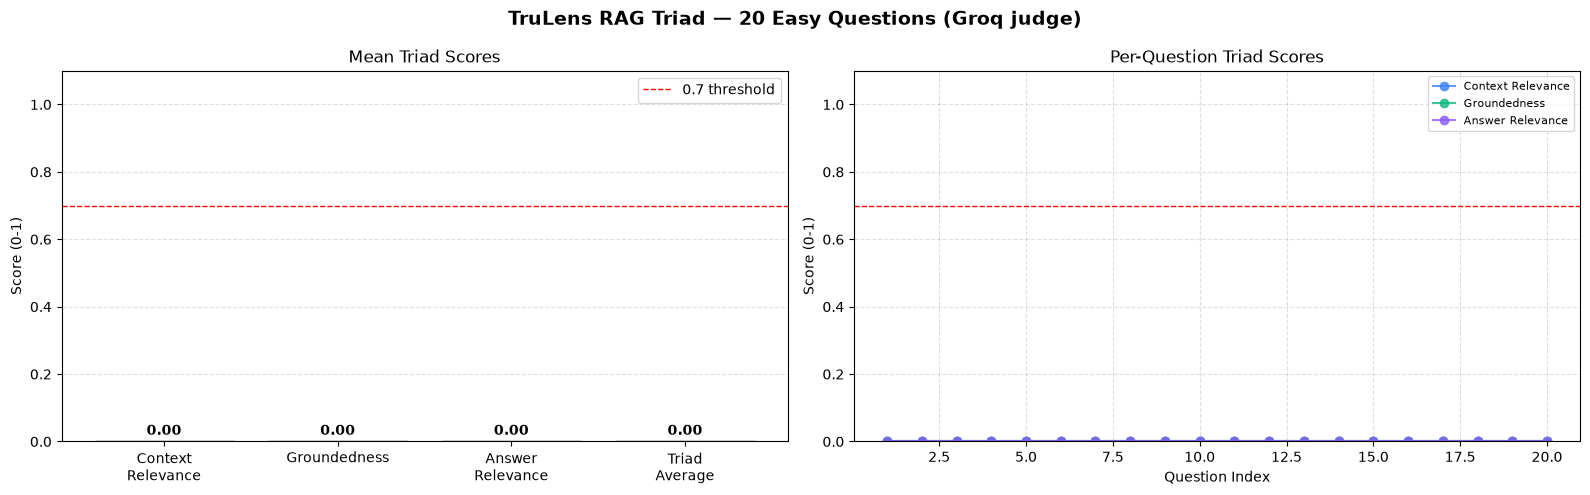

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("TruLens RAG Triad — 20 Easy Questions (Groq judge)", fontsize=14, fontweight="bold")

dims   = ["Context\nRelevance", "Groundedness", "Answer\nRelevance", "Triad\nAverage"]
cols   = ["context_relevance", "groundedness", "answer_relevance", "triad_average"]
colors = ["#3b82f6", "#10b981", "#8b5cf6", "#f59e0b"]
means  = [triad_df[c].mean() for c in cols]

bars = axes[0].bar(dims, means, color=colors, edgecolor="black", alpha=0.85)
axes[0].set_ylim(0, 1.1)
axes[0].set_ylabel("Score (0-1)")
axes[0].set_title("Mean Triad Scores")
axes[0].axhline(0.7, color="red", linestyle="--", linewidth=1, label="0.7 threshold")
axes[0].legend()
for bar, val in zip(bars, means):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f"{val:.2f}", ha="center", fontsize=10, fontweight="bold")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

for col, label, color in zip(cols[:3], dims[:3], colors[:3]):
    axes[1].plot(range(1, len(triad_df)+1), triad_df[col], "o-", label=label.replace("\n", " "), color=color, alpha=0.8)
axes[1].set_xlabel("Question Index")
axes[1].set_ylabel("Score (0-1)")
axes[1].set_title("Per-Question Triad Scores")
axes[1].set_ylim(0, 1.1)
axes[1].axhline(0.7, color="red", linestyle="--", linewidth=1)
axes[1].legend(fontsize=8)
axes[1].grid(linestyle="--", alpha=0.4)

(BASE_DIR / "evaluation" / "scorecards").mkdir(parents=True, exist_ok=True)
plt.tight_layout()
plt.savefig(BASE_DIR / "evaluation" / "scorecards" / "04_trulens_triad.png", dpi=120, bbox_inches="tight")
plt.show()


## 6. Chain-of-Thought Reasoning Sample

In [7]:
# Inspect the judge's reasoning for the first question
sample = triad_df.iloc[0]
print(f"Question : {sample['question']}")
print(f"\nContext Relevance  ({sample['context_relevance']:.2f}):")
print(f"  {sample['ctx_reason'][:300]}")
print(f"\nGroundedness       ({sample['groundedness']:.2f}):")
print(f"  {sample['gr_reason'][:300]}")
print(f"\nAnswer Relevance   ({sample['answer_relevance']:.2f}):")
print(f"  {sample['ar_reason'][:300]}")


Question : What was JPMorgan Chase's total net revenue for the year ended December 31, 2025?

Context Relevance  (0.00):
  Error code: 404 - {'error': {'message': 'The model `llama-3.3-70b-versatile` does not exist or you do not have access to it.', 'type': 'invalid_request_error', 'code': 'model_not_found'}}

Groundedness       (0.00):
  Endpoint is not set.

Answer Relevance   (0.00):
  Error code: 404 - {'error': {'message': 'The model `llama-3.3-70b-versatile` does not exist or you do not have access to it.', 'type': 'invalid_request_error', 'code': 'model_not_found'}}
